# EDA — Predicción de Popularidad de Canciones en Spotify
### Evaluación Parcial N°1 — MLY1101 Machine Learning

Este notebook continúa el proyecto a partir del dataset limpio (`data/processed/spotify_tracks_clean.csv`), generado en `01_preparacion_datos.ipynb`. Se realiza el análisis exploratorio de datos (EDA) y la evaluación de sesgos, ética y privacidad.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

df = pd.read_csv('../data/processed/spotify_tracks_clean.csv')
print(df.shape)
df.head()

(113549, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Análisis exploratorio de los datos (EDA)

### 3.1 Distribución de la variable objetivo: `popularity`

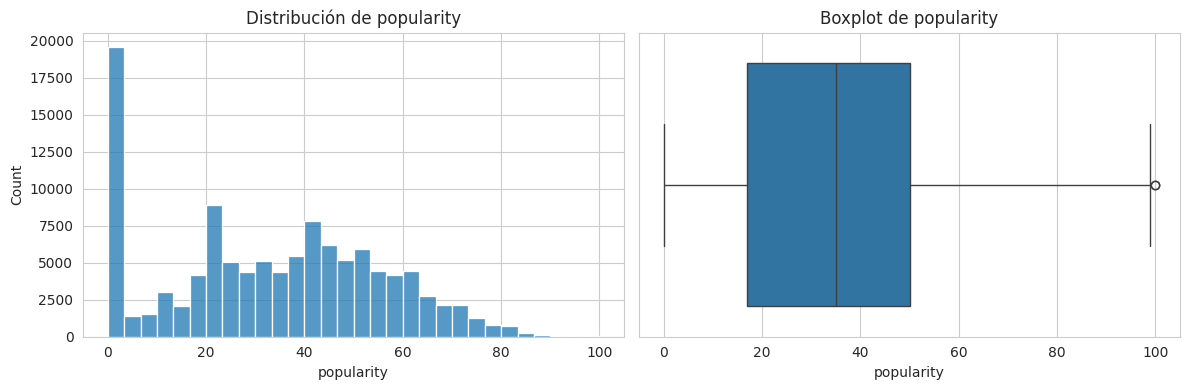

count    113549.000000
mean         33.324433
std          22.283855
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['popularity'], bins=30, ax=axes[0])
axes[0].set_title('Distribución de popularity')

sns.boxplot(x=df['popularity'], ax=axes[1])
axes[1].set_title('Boxplot de popularity')

plt.tight_layout()
plt.savefig('../images/distribucion_popularity.png', dpi=100)
plt.show()

df['popularity'].describe()

**Hallazgo:** la distribución de `popularity` está sesgada hacia valores bajos-medios, con una acumulación notoria en 0 (~14% de las canciones). Esto sugiere que muchas canciones del dataset prácticamente no tuvieron reproducciones relevantes, lo cual es esperable en un catálogo tan amplio (114.000 canciones de 125 géneros).

### 3.2 Relación entre audio features y popularity

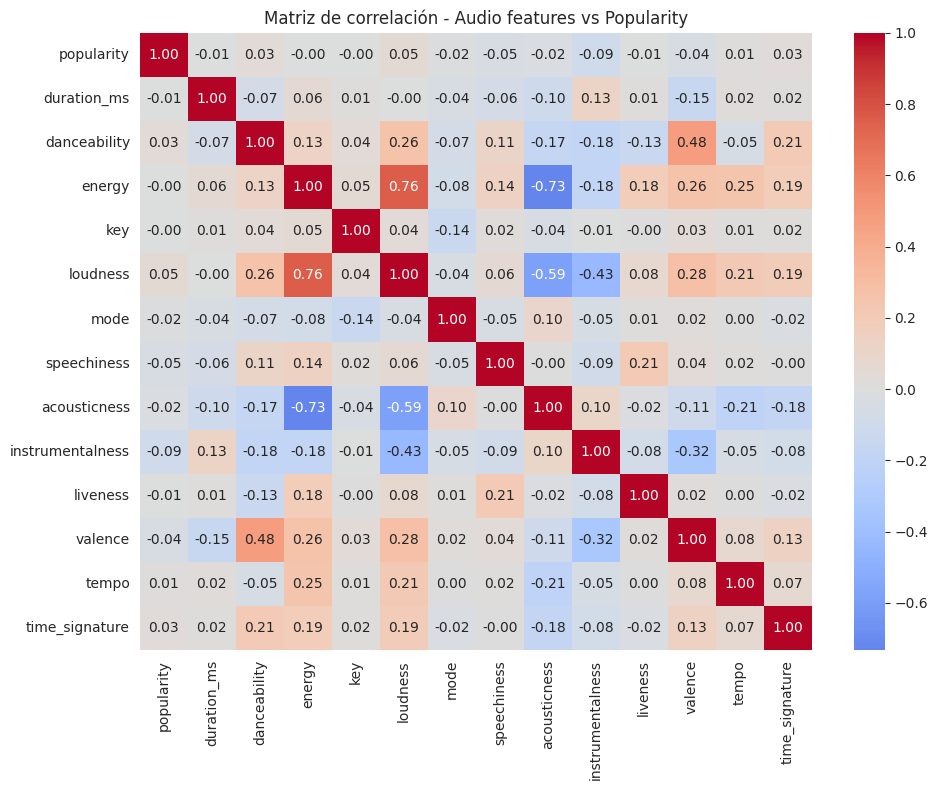

popularity          1.000000
loudness            0.047368
danceability        0.034407
time_signature      0.030567
tempo               0.012187
energy             -0.002447
key                -0.004167
liveness           -0.005668
duration_ms        -0.007928
mode               -0.015009
acousticness       -0.022356
valence            -0.041097
speechiness        -0.045463
instrumentalness   -0.094718
Name: popularity, dtype: float64

In [ ]:
num_cols = ['popularity','duration_ms','danceability','energy','key','loudness','mode',
            'speechiness','acousticness','instrumentalness','liveness','valence','tempo','time_signature']

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación - Audio features vs Popularity')
plt.tight_layout()
plt.savefig('../images/correlacion_features.png', dpi=100)
plt.show()

corr['popularity'].sort_values(ascending=False)

**Hallazgo clave:** ninguna audio feature individual tiene una correlación relevante con `popularity` (todas por debajo de 0.1 en valor absoluto). `loudness` y `danceability` son las más asociadas positivamente, e `instrumentalness` y `speechiness` las más asociadas negativamente, pero ninguna alcanza una correlación fuerte. Esto indica que la popularidad de una canción **no se explica solo por sus características acústicas** — probablemente influyen más factores externos como el artista, la promoción, el género o la fecha de lanzamiento (no disponible en este dataset).

### 3.3 Popularidad por género musical

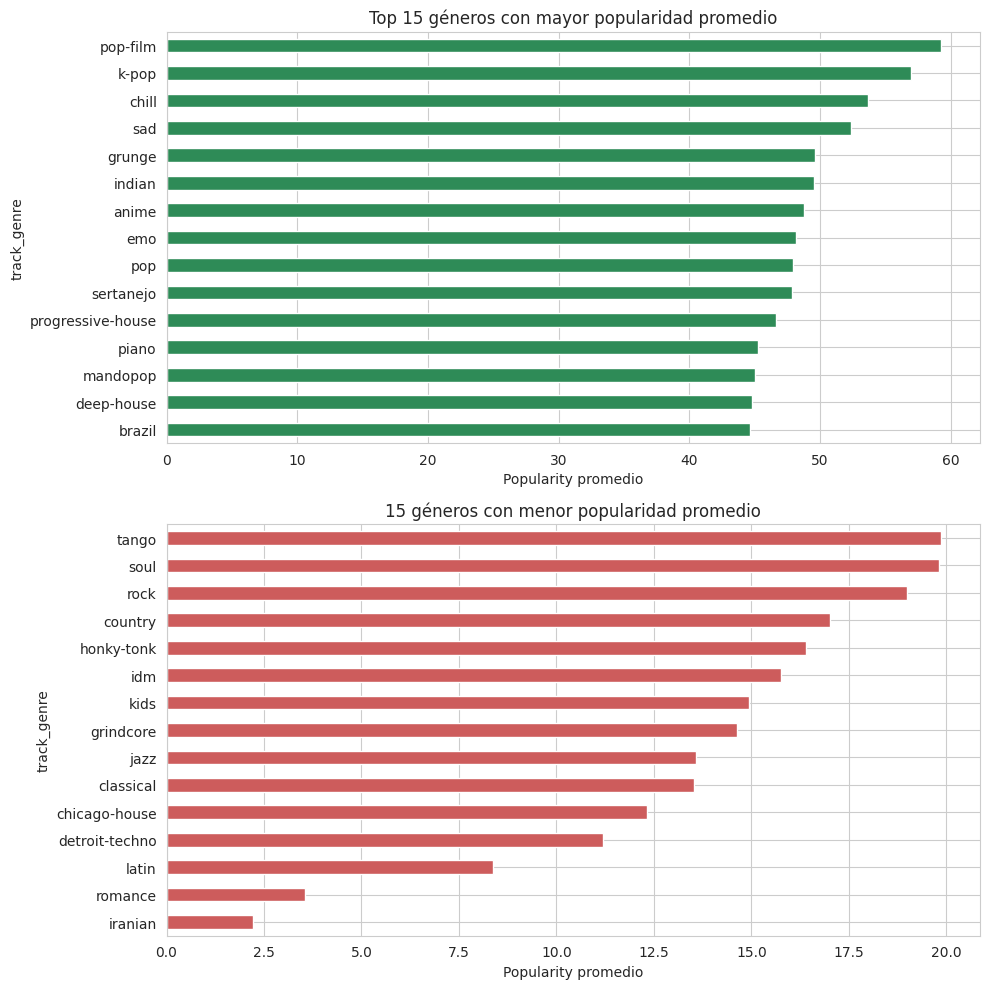

In [ ]:
pop_por_genero = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

pop_por_genero.head(15).plot(kind='barh', ax=axes[0], color='seagreen')
axes[0].invert_yaxis()
axes[0].set_title('Top 15 géneros con mayor popularidad promedio')
axes[0].set_xlabel('Popularity promedio')

pop_por_genero.tail(15).plot(kind='barh', ax=axes[1], color='indianred')
axes[1].invert_yaxis()
axes[1].set_title('15 géneros con menor popularidad promedio')
axes[1].set_xlabel('Popularity promedio')

plt.tight_layout()
plt.savefig('../images/popularidad_por_genero.png', dpi=100)
plt.show()

**Hallazgo:** a diferencia de las audio features, **el género sí marca una diferencia grande** en la popularidad promedio: géneros como `pop-film`, `k-pop` y `chill` superan los 50 puntos de popularidad promedio, mientras que géneros como `iranian`, `romance` o `latin` (en esta muestra) apenas superan los 2-8 puntos. Esto sugiere que `track_genre` será una variable predictora relevante para el modelo, más que las audio features individuales.

### 3.4 Canciones explícitas vs no explícitas

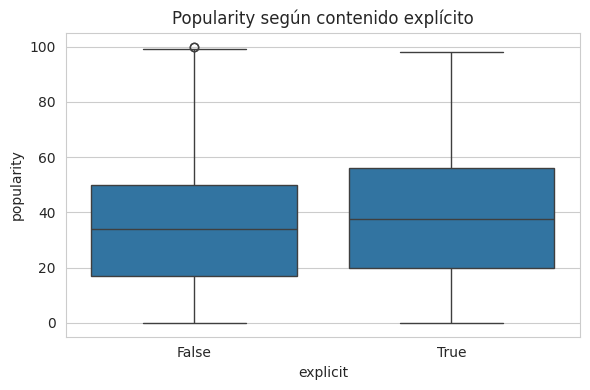

explicit
False    33.024896
True     36.524799
Name: popularity, dtype: float64

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(x='explicit', y='popularity', data=df, ax=ax)
ax.set_title('Popularity según contenido explícito')
plt.tight_layout()
plt.savefig('../images/popularity_explicit.png', dpi=100)
plt.show()

df.groupby('explicit')['popularity'].mean()

## 4. Evaluación de sesgos, ética y privacidad de los datos

**Privacidad:** el dataset no contiene datos personales de usuarios (no hay IDs de oyentes, ubicación ni historial de reproducción individual); solo metadatos públicos de canciones (nombre, artista, álbum) y métricas agregadas calculadas por Spotify. El riesgo de privacidad es bajo.

**Sesgos identificados:**
- **Sesgo de género musical:** el dataset no tiene una distribución equilibrada de popularidad entre géneros — géneros mainstream (pop, k-pop) están sobrerrepresentados en popularidad frente a géneros de nicho (iranian, romance, idm). Un modelo entrenado con estos datos podría aprender a favorecer patrones de géneros populares y predecir sistemáticamente baja popularidad para géneros minoritarios, incluso si una canción específica es de buena calidad.
- **Sesgo de "estrella" (long tail):** ~14% de las canciones tienen popularity = 0, lo que refleja cómo unos pocos artistas/canciones concentran la mayoría de las reproducciones (fenómeno long-tail típico de plataformas de streaming). Esto puede sesgar el modelo hacia predecir valores bajos por defecto.
- **Ausencia de variables temporales y de contexto:** no hay fecha de lanzamiento, país de origen del oyente, ni datos de campañas de marketing, factores que en la realidad influyen fuertemente en la popularidad. El modelo solo puede capturar la relación entre audio features/género y popularidad, no factores externos (esto es una limitación, no solo un sesgo).

**Mitigación propuesta:** documentar estas limitaciones en las conclusiones del proyecto y evitar presentar el modelo como una herramienta de decisión única para promocionar música — debe usarse como apoyo, no reemplazo del criterio humano/experto en A&R (Artists & Repertoire).
